## Configurar o uso da GPU (Nvidia e AMD)

In [ ]:
import torch
from ultralytics import YOLO

def definir_dispositivo_teste():
    """
    Detecta o hardware disponível para acelerar os testes (inferência).
    Retorna o dispositivo e um booleano indicando se é AMD (DirectML).
    """
    # 1. Verifica se há GPU NVIDIA (CUDA)
    if torch.cuda.is_available():
        print("🚀 GPU NVIDIA Detectada! Testes rodarão via CUDA.")
        return "cuda:0", False

    # 2. Verifica se há GPU AMD/Intel (DirectML no Windows)
    try:
        import torch_directml
        # Força uma inicialização de teste para garantir que o DirectML está conversando com placas AMD
        dml_device = torch_directml.device()
        print(f"🚀 GPU AMD/Intel Detectada! Testes rodarão via DirectML ({dml_device}).")
        return dml_device, True
    except Exception as e:
        print(f"⚠️ Nota sobre AMD: DirectML não inicializado ou indisponível. Motivo: {e}")

    # 3. Fallback para CPU
    print("💻 Nenhuma GPU detectada ou configurada. Os testes rodarão no CPU.")
    return "cpu", False

# Define as variáveis globais de hardware
DISPOSITIVO_TESTE, EH_AMD = definir_dispositivo_teste()


⚠️ Nota sobre AMD: DirectML não inicializado ou indisponível. Motivo: No module named 'torch_directml'
💻 Nenhuma GPU detectada ou configurada. Os testes rodarão no CPU.


## Carregando o modelo e preparando os caminhos dos arquivos

In [ ]:
import os
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# 1. Defina o dataset que será validado neste momento (Ex: 'placas', 'ingredientes')
DATASET_ATIVO = "placas" 
ARQUIVO_CONFIG = f"../data_{DATASET_ATIVO}.yaml"

# 2. Carrega o modelo (Aponte para o modelo padrão ou para o seu customizado após o treino)
MODELO_PATH = "../models/yolov8s.pt" # Baseline padrão
# MODELO_PATH = f"../models/treinamentos/yolo_{DATASET_ATIVO}/weights/best.pt"

print(f"Carregando o modelo: {MODELO_PATH}")
model = YOLO(MODELO_PATH)

# Envia o modelo para o hardware correto (NVIDIA, AMD ou CPU)
if EH_AMD:
    # Placas AMD exigem o envio explícito via PyTorch .to()
    model.to(DISPOSITIVO_TESTE)
    print(f"Modelo carregado com sucesso na GPU/Dispositivo: {DISPOSITIVO_TESTE}")
else:
    # NVIDIA e CPU aceitam a definição direta ou interna do YOLO
    model.to(DISPOSITIVO_TESTE)
    print(f"Modelo carregado com sucesso na GPU/Dispositivo: {DISPOSITIVO_TESTE}")


Carregando o modelo: ../models/yolov8s.pt


## TESTE 1 – Inferência em uma única Imagem Individual


image 1/1 e:\Users\Dani\Documents\Daniel\sc tec\Carreira Tech - Trilha Inteligncia Artificial\Fundamentos de Programao Dados e Machine Learning T1\Mod 2\Projeto Final\SC-Tec-Mod2-Final-Deteccao-Objetos-API\notebooks\..\tests\placas\lampu-hijau--95-_jpg.rf.16fb6212da51e975031103a45d1e65d7.jpg: 640x640 (no detections), 631.5ms
Speed: 24.0ms preprocess, 631.5ms inference, 20.4ms postprocess per image at shape (1, 3, 640, 640)

--- DETECÇÕES ESTRUTURADAS (SAÍDA JSON DA API) ---

--- VISUALIZAÇÃO GRÁFICA ---


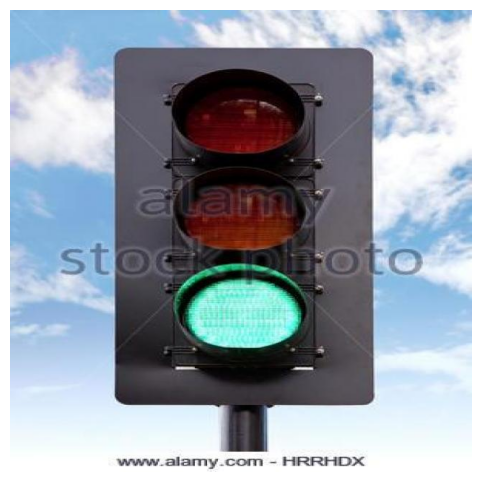

In [2]:
# Defina o caminho de uma imagem de teste avulsa
IMAGEM_TESTE = "../tests/placas/lampu-hijau--95-_jpg.rf.16fb6212da51e975031103a45d1e65d7.jpg"

# Executa a inferência
resultados = model(IMAGEM_TESTE)

# Mostra as saídas brutas estruturadas no terminal/célula
print("\n--- DETECÇÕES ESTRUTURADAS (SAÍDA JSON DA API) ---")
for result in resultados:
    boxes = result.boxes
    for box in boxes:
        conf = float(box.conf)
        cls_id = int(box.cls)
        nome_classe = model.names[cls_id]
        
        if conf > 0.4:  # Filtro de confiança mínima
            x_min, y_min, x_max, y_max = box.xyxy.tolist()[0]
            print(f"Classe: {nome_classe} | Confiança: {conf:.2f} | BBox: [{int(x_min)}, {int(y_min)}, {int(x_max)}, {int(y_max)}]")

# Exibe o resultado visual desenhado diretamente na tela do Notebook
print("\n--- VISUALIZAÇÃO GRÁFICA ---")
imagem_desenhada = resultados[0].plot()
imagem_rgb = cv2.cvtColor(imagem_desenhada, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(imagem_rgb)
plt.axis('off')
plt.show()

## TESTE 2 – Métricas Isoladas de uma Classe Específica

In [5]:
# Executa a validação oficial do YOLO no dataset ativo
metrics = model.val(data=ARQUIVO_CONFIG, split="val", plots=False)

# Altere o nome abaixo para a classe exata que você deseja inspecionar
CLASSE_ALVO = "do_not_enter" 

# Descobre o ID correspondente ao nome da classe alvo
id_classe_alvo = None
for idx, name in model.names.items():
    if name == CLASSE_ALVO:
        id_classe_alvo = idx
        break

if id_classe_alvo is not None:
    # Extrai as métricas de Precision, Recall e mAP50 para a classe alvo
    precision_classe = metrics.precision[id_classe_alvo]
    recall_classe = metrics.recall[id_classe_alvo]
    map50_classe = metrics.map50[id_classe_alvo]
    
    print(f"=== MÉTRICAS ISOLADAS PARA A CLASSE: '{CLASSE_ALVO.upper()}' ===")
    print(f"Precisão (Precision): {precision_classe:.4f}")
    print(f"Revocação (Recall):    {recall_classe:.4f}")
    print(f"mAP50 da Classe:       {map50_classe:.4f}")
else:
    print(f"Classe '{CLASSE_ALVO}' não encontrada no mapeamento do arquivo yaml.")

Ultralytics 8.4.171  Python-3.14.5 torch-2.14.1+cpu CPU (Intel Core i5-3330 3.00GHz)
YOLOv8s summary (fused): 72 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.20.0 ms, read: 1.60.7 MB/s, size: 34.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\projeto dataset\road signs.v2\valid\labels... 488 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 488/488 58.8it/s 8.3s0.1s
val: New cache created: E:\projeto dataset\road signs.v2\valid\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 8.7s/it 4:308.5ss
                   all        488        529    0.00661      0.117    0.00175   0.000798
               bicycle         30         30   0.000866     0.0333   0.000157   1.57e-05
                   car         30         30          0          0     

## TESTE 3 – Métricas Globais e Classification Report de Todo o Dataset

In [ ]:
import pandas as pd

# Executa novamente habilitando a geração dos gráficos visuais
print("Processando todas as classes para gerar o relatório final...")
metrics_globais = model.val(data=ARQUIVO_CONFIG, split="val", plots=True)

# 1. Constrói o Classification Report estruturado em tabela
classes_mapeadas = list(model.names.values())
report_data = {
    "Classe": classes_mapeadas,
    "Precisão (Precision)": [float(p) for p in metrics_globais.precision],
    "Revocação (Recall)": [float(r) for r in metrics_globais.recall],
    "mAP50": [float(m) for m in metrics_globais.map50],
    "mAP50-95": [float(m) for m in metrics_globais.map95]
}

df_report = pd.DataFrame(report_data)

# 2. Adiciona a linha de média global (Macro Average)
linha_media = pd.DataFrame([{
    "Classe": "MÉDIA GLOBAL (all)",
    "Precisão (Precision)": float(metrics_globais.box.mp),
    "Revocação (Recall)": float(metrics_globais.box.mr),
    "mAP50": float(metrics_globais.box.map50),
    "mAP50-95": float(metrics_globais.box.map)
}])
df_report = pd.concat([df_report, linha_media], ignore_index=True)

# Exibe o relatório tabular estilizado
pd.set_option('display.float_format', lambda x: '%.4f' % x)
print("\n======================= CLASSIFICATION REPORT (YOLO) =======================")
display(df_report)

# 3. Exibe o gráfico da Matriz de Confusão para fechar a análise do vídeo
caminho_matriz = os.path.join(metrics_globais.save_dir, "confusion_matrix.png")
if os.path.exists(caminho_matriz):
    print("\n--- MATRIZ DE CONFUSÃO DO DATASET ---")
    matriz_img = cv2.imread(caminho_matriz)
    matriz_rgb = cv2.cvtColor(matriz_img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(11, 9))
    plt.imshow(matriz_rgb)
    plt.axis('off')
    plt.show()